## חקירת משתנה המטרה: annual_claim_cost
עלות התביעות השנתית של הנהג בשקלים, זה מה שהמודל צריך לחזות.

נבדוק ערכים חסרים, כמה נהגים לא תבעו בכלל, ואת צורת ההתפלגות.

In [1]:
# טעינת הדאטה ובדיקה ראשונית של משתנה המטרה
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
df = pd.read_csv("dataset.csv")
y = df["annual_claim_cost"]

print("Missing:", y.isna().sum())
print("Share of zeros:", round((y == 0).mean(), 3))
y.describe().round(0)

Missing: 0
Share of zeros: 0.649


count     45000.0
mean       3051.0
std        7552.0
min           0.0
25%           0.0
50%           0.0
75%        3114.0
max      224808.0
Name: annual_claim_cost, dtype: float64

### הנהגים שתבעו, וריכוז העלות
נבדוק את ההתפלגות רק אצל הנהגים שתבעו, ואיזה חלק מכלל העלות מגיע מהנהגים היקרים ביותר.

In [2]:
# התפלגות העלות רק אצל הנהגים שתבעו, וחלק העלות הכוללת של הנהגים היקרים ביותר
claims = y[y > 0]
print("Drivers with a claim:", len(claims))
print(claims.describe().round(0), "\n")

sorted_cost = y.sort_values(ascending=False)
total = sorted_cost.sum()
for pct in [0.01, 0.05, 0.10]:
    n = int(len(y) * pct)
    print(f"Top {int(pct * 100)}% of drivers ({n}) = {sorted_cost.iloc[:n].sum() / total:.1%} of total cost")

print("\nDrivers above 10,000:", (y > 10000).sum(), f"({(y > 10000).mean():.1%})")

Drivers with a claim: 15793
count     15793.0
mean       8693.0
std       10652.0
min         600.0
25%        2773.0
50%        5359.0
75%       10374.0
max      224808.0
Name: annual_claim_cost, dtype: float64 

Top 1% of drivers (450) = 17.4% of total cost
Top 5% of drivers (2250) = 46.5% of total cost
Top 10% of drivers (4500) = 66.0% of total cost

Drivers above 10,000: 4159 (9.2%)


### התפלגות העלות אצל מי שתבע
בסקאלה רגילה ובסקאלה לוגריתמית. הקו האדום מסמן נהג יקר, מעל עשרת אלפים.

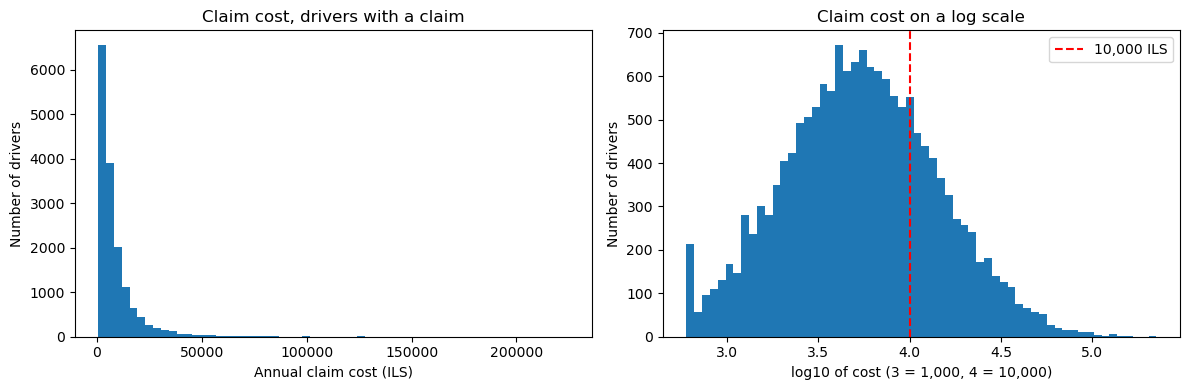

In [3]:
# היסטוגרמה של העלות אצל מי שתבע בסקאלה רגילה ובסקאלה לוגריתמית
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(claims, bins=60)
axes[0].set_title("Claim cost, drivers with a claim")
axes[0].set_xlabel("Annual claim cost (ILS)")
axes[0].set_ylabel("Number of drivers")

axes[1].hist(np.log10(claims), bins=60)
axes[1].axvline(np.log10(10000), color="red", linestyle="--", label="10,000 ILS")
axes[1].set_title("Claim cost on a log scale")
axes[1].set_xlabel("log10 of cost (3 = 1,000, 4 = 10,000)")
axes[1].set_ylabel("Number of drivers")
axes[1].legend()

plt.tight_layout()
plt.show()

### האם הנחת נורמליות מתאימה לעלות
נשווה בין ההסתברות לפי התפלגות נורמלית עם הממוצע וסטיית התקן של הדאטה, לבין מה שקורה בפועל.

In [4]:
# השוואה בין ההסתברות לפי הנחת נורמליות לבין השכיחות בפועל בכמה ספים
from scipy.stats import norm

mean, std = y.mean(), y.std()
print(f"Normal: probability of a negative cost = {norm.cdf(0, mean, std):.1%}\n")
for t in [10000, 30000, 50000, 100000]:
    print(f"Above {t:>7,}: normal {norm.sf(t, mean, std):.4%} | actual {(y > t).mean():.4%} ({(y > t).sum()} drivers)")

Normal: probability of a negative cost = 34.3%

Above  10,000: normal 17.8736% | actual 9.2422% (4159 drivers)
Above  30,000: normal 0.0179% | actual 1.4600% (657 drivers)
Above  50,000: normal 0.0000% | actual 0.3867% (174 drivers)
Above 100,000: normal 0.0000% | actual 0.0422% (19 drivers)


### מסקנות לגבי משתנה המטרה
- **אין ערכים חסרים.** 45,000 נהגים, עלות בין 0 ל-224,808.
- **65% לא תבעו**, ולכן החציון הוא 0 והממוצע (3,051) לא מייצג אף נהג אמיתי. אצל מי שתבע (35%), החציון הוא 5,359.
- **ריכוז העלות:** 1% מהנהגים אחראים ל-17% מהעלות, 5% ל-47%, ו-10% ל-66%. נהג יקר (מעל 10,000): 9.2%.
- **הטיה ימינה חזקה** (skew 4.4 אצל מי שתבע). בסקאלה לוגריתמית ההתפלגות כמעט סימטרית (skew 0.1), כלומר בערך לוג-נורמלית.
- **600 ₪ הוא כנראה סכום מינימלי לתביעה:** 163 נהגים בדיוק ב-600, והכפולות 1,200 ו-1,800 מתאימות ל-2 ו-3 תביעות.
- **הנחת נורמליות לא מתאימה:** היא נותנת 34% לעלות שלילית, מגזימה פי 2 סביב 10,000, וממעיטה מאוד בזנב (לפיה כמעט אין נהגים מעל 50,000, ובפועל יש 174).
- **קו בסיס:** מודל שתמיד חוזה את הממוצע נותן RMSE של 7,552, MAE של 4,196 ו-R² של 0. כל מודל שנבנה צריך להיות טוב יותר.
- **השלכות:** ElasticNet יתקשה בזנב ועלול לחזות עלויות שליליות. רוב ה-RMSE יגיע מהנהגים היקרים, ולכן נדווח גם RMSE וגם MAE.

## סעיף 2.3: עלות התביעות לפי גיל הנהג
נבנה מודל לינארי פשוט עם משתנה אחד, גיל הנהג, ונבקש ממנו קו מגמה לגילאים 0 עד 100. בדאטה יש רק גילאי 18 עד 90.

In [5]:
# מודל לינארי עם גיל הנהג בלבד, ותחזית לכמה גילאים לאורך הטווח המבוקש
from sklearn.linear_model import LinearRegression

print("Age range in data:", df["driver_age"].min(), "to", df["driver_age"].max())

X_age = df[["driver_age"]]
age_model = LinearRegression().fit(X_age, y)
print(f"Intercept: {age_model.intercept_:.1f}")
print(f"Slope: {age_model.coef_[0]:.2f} per year")
print(f"R2: {age_model.score(X_age, y):.4f}\n")

check_ages = pd.DataFrame({"driver_age": [0, 18, 30, 50, 70, 90, 100]})
pred = pd.Series(age_model.predict(check_ages).round(0), index=check_ages["driver_age"], name="line")
actual = y.groupby(df["driver_age"]).mean().round(0).rename("actual_mean")
pd.concat([pred, actual], axis=1).loc[check_ages["driver_age"]]

Age range in data: 18 to 90
Intercept: 4933.6
Slope: -39.22 per year
R2: 0.0074



,line,actual_mean
driver_age,,
0,4934.0,NaN
18,4228.0,8492.0
30,3757.0,3343.0
50,2973.0,2616.0
70,2189.0,1807.0
90,1404.0,4404.0
100,1012.0,NaN


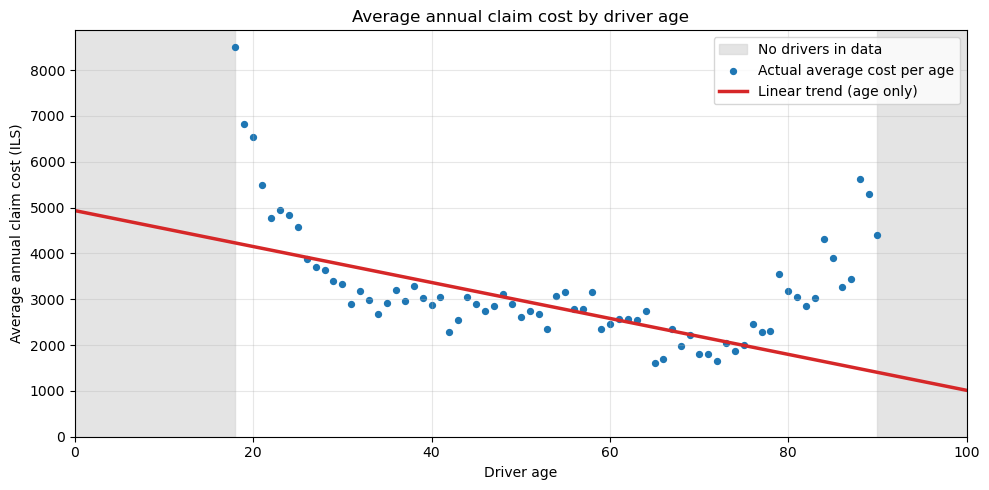

In [6]:
# גרף למנהל: הממוצע האמיתי בכל גיל, קו המגמה לגילאי אפס עד מאה, וסימון הטווח שאין בו נתונים
all_ages = pd.DataFrame({"driver_age": np.arange(0, 101)})
line = age_model.predict(all_ages)
mean_by_age = y.groupby(df["driver_age"]).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(0, 18, color="lightgray", alpha=0.6, label="No drivers in data")
ax.axvspan(90, 100, color="lightgray", alpha=0.6)
ax.scatter(mean_by_age.index, mean_by_age.values, color="tab:blue", s=18, label="Actual average cost per age")
ax.plot(all_ages["driver_age"], line, color="tab:red", linewidth=2.5, label="Linear trend (age only)")

ax.set_title("Average annual claim cost by driver age")
ax.set_xlabel("Driver age")
ax.set_ylabel("Average annual claim cost (ILS)")
ax.set_xlim(0, 100)
ax.set_ylim(0, None)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### מסקנות סעיף 2.3
- **הקו:** העלות יורדת ב-39 ₪ לכל שנת גיל. R² הוא 0.007, כלומר הגיל לבדו מסביר פחות מ-1% מהפיזור בעלות.
- **הקו מפספס את צורת ה-U:** בגיל 18 הוא חוזה 4,228 ובפועל 8,492, ובגיל 90 הוא חוזה 1,404 ובפועל 4,404. נהגים צעירים ומבוגרים יקרים, וקו ישר לא יכול לתאר את זה.
- **מחוץ לטווח הנתונים (0 עד 17 ו-91 עד 100) הקו לא אמין:** הוא חוזה 4,934 ₪ לגיל 0, גיל שבו אי אפשר לנהוג. זו אקסטרפולציה, ואסור להציג אותה למנהל כאילו היא מבוססת על נתונים.
- **המלצה למנהל:** לא לתמחר לפי הקו. להשתמש בו רק בטווח 18 עד 90, ולזכור שהוא ממעיט בעלות של הצעירים והמבוגרים.
- **השלכה למודל:** צריך פיצ'רים שמאפשרים צורת U, למשל גיל בריבוע ודגל נהג צעיר (בלוק 2).